In [1]:
print(1)

1


In [2]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import mean_squared_error,r2_score
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor,AdaBoostRegressor
from sklearn.svm import SVR
from sklearn.model_selection import RandomizedSearchCV
from catboost import CatBoostRegressor
from xgboost import XGBRegressor

In [5]:
df = pd.read_csv("data/stud.csv")

In [6]:
df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [7]:
X= df.drop(columns=["math score"],axis=1)
y = df["math score"]

X

,gender,race/ethnicity,parental level of education,lunch,test preparation course,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,74
1,female,group C,some college,standard,completed,90,88
2,female,group B,master's degree,standard,none,95,93
3,male,group A,associate's degree,free/reduced,none,57,44
4,male,group C,some college,standard,none,78,75
...,...,...,...,...,...,...,...
995,female,group E,master's degree,standard,completed,99,95
996,male,group C,high school,free/reduced,none,55,55
997,female,group C,high school,free/reduced,completed,71,65
998,female,group D,some college,standard,completed,78,77


In [8]:
num_features = X.select_dtypes(exclude="object").columns
cat_features = X.select_dtypes(include="object").columns
from sklearn.preprocessing import StandardScaler,OneHotEncoder
from sklearn.compose import ColumnTransformer

scaler = StandardScaler()
encoder = OneHotEncoder()
preprocessor = ColumnTransformer(
    [
        ("OneHotEncoder",encoder,cat_features),
        ("StandardScaler",scaler,num_features),
    ]
)

In [9]:
X = preprocessor.fit_transform(X)

In [12]:
X.shape

(1000, 19)

In [14]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)
X_train.shape ,X_test.shape

((800, 19), (200, 19))

In [15]:
from sklearn.metrics import mean_absolute_error
def perform_model(true,pred):
    mae = mean_absolute_error(true,pred)
    mse = mean_squared_error(true,pred)
    r2 = r2_score(true,pred)
    rmse = np.sqrt(mse)
    return mae ,rmse,r2

In [18]:
from sklearn.linear_model import LinearRegression,Lasso,Ridge
models = {
    "LinearRegression" : LinearRegression(),
    "Lasso": Lasso(),
    "Ridge": Ridge(),
    "KNeighborsRegressor":KNeighborsRegressor(),
    "DecisionTreeRegressor":DecisionTreeRegressor(),
    "RandomForestRegressor": RandomForestRegressor(),
    "XGBRegressor":XGBRegressor(),
    "CatBoostRegressor": CatBoostRegressor(),
    "AdaBoostRegressor": AdaBoostRegressor()
}
model_list = []
r2_list=[]
for name,model in models.items():
    model.fit(X_train,y_train)
    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)

    model_train_mae , model_train_rmse , model_train_r2 = perform_model(y_train,y_train_pred)
    model_test_mae , model_test_rmse , model_test_r2 = perform_model(y_test,y_test_pred)
    print(f" {name} ::Model Performance for training data ")
    model_list.append(name)
    r2_list.append(model_test_r2)
    print("Root mean squared error:" , model_train_rmse)
    print("Mean absolute error:",model_train_mae)
    print("R2 score: ",model_train_r2)
    print("-----------------------------------------------")
    print(f"{name} ::Model performance for test data")
    print()
    print("Root mean squared error:" , model_test_rmse)
    print("Mean squared  error:" , model_test_mae)
    print("R2 score:" , model_test_r2)
    print("-----------------------------------------------")

 LinearRegression ::Model Performance for training data 
Root mean squared error: 5.324354270503339
Mean absolute error: 4.267138671875
R2 score:  0.8742556463650867
-----------------------------------------------
LinearRegression ::Model performance for test data

Root mean squared error: 5.3959872842671395
Mean squared  error: 4.2158203125
R2 score: 0.8803449074540941
-----------------------------------------------
 Lasso ::Model Performance for training data 
Root mean squared error: 6.593815587795566
Mean absolute error: 5.206302661246526
R2 score:  0.8071462015863456
-----------------------------------------------
Lasso ::Model performance for test data

Root mean squared error: 6.519694535667419
Mean squared  error: 5.157881810347763
R2 score: 0.8253197323627853
-----------------------------------------------
 Ridge ::Model Performance for training data 
Root mean squared error: 5.323324922741654
Mean absolute error: 4.26498782372598
R2 score:  0.8743042615212909
----------------

In [21]:
pd.DataFrame(list(zip(model_list,r2_list)),columns=["Model","R2_Score"]).sort_values(by=["R2_Score"],ascending=False)

,Model,R2_Score
2,Ridge,0.880593
0,LinearRegression,0.880345
5,RandomForestRegressor,0.851693
7,CatBoostRegressor,0.851632
8,AdaBoostRegressor,0.850748
6,XGBRegressor,0.827797
1,Lasso,0.825320
3,KNeighborsRegressor,0.783813
4,DecisionTreeRegressor,0.748129


Görülen o ki Ridge ve Linear regression en iyi sonuçları veriyor ve biz burda Linear Regression dan devam edebiliriz çünkü Ridge ile aralarında neredeyse hiç ama hiç fark yok 


In [22]:
lin_model = LinearRegression(fit_intercept=True)
lin_model.fit(X_train,y_train)
y_pred = lin_model.predict(X_test)
score = r2_score(y_test,y_pred)*100
print("Accuracy of the model is %", score)

Accuracy of the model is % 88.03449074540941


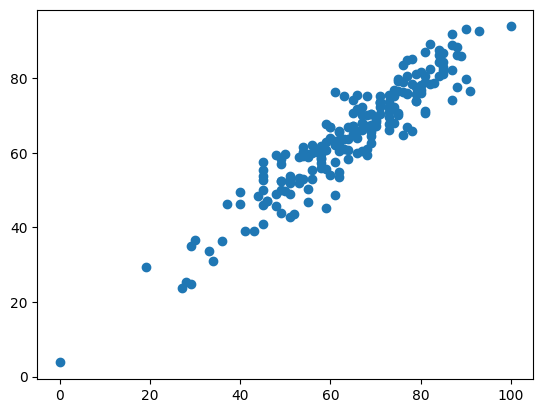

In [23]:
plt.scatter(y_test,y_pred)
